# Premier League Player Performance Analysis (2025/26)

## Data Acquisition Project

### Research Question

**How do expected goals (xG), expected assists (xA), and passing accuracy relate to player performance in the 2025/26 Premier League?**

### Project Overview

The project looks into the relationships between expected attacking statistics, passing accuracy and player performance in the 2025/26 Premier League.

Two datasets are used:

1. **Kaggle:** Football Players Stats 2025–2026, containing 2,839 player records across five major European leagues.
2. **Statto:** Premier League Player Statistics 2025/26, a website that has player statistics including expected goals (xG), expected assists (xA) and pass completion percentage.

The Statto data is collected using web scraping and combined with the Kaggle dataset using player names and team names.

The project uses pandas for data preparation and Seaborn for visualisation to investigate how these statistics relate to goals and assists.

### Data Sources

- Kaggle: https://www.kaggle.com/datasets/hubertsidorowicz/football-players-stats-2025-2026
- Statto: https://statto.pythonanywhere.com/stats/players?sort=player_name&dir=asc&limit=all

### Tools I Used

Python, Google Colab, pandas, Requests, BeautifulSoup, Matplotlib and Seaborn.

In [1]:
import pandas as pd
import numpy as np
import requests
from bs4 import BeautifulSoup
from io import StringIO
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

## 1. Kaggle Dataset: Import and Exploration

The original dataset was downloaded from Kaggle and it has football player statistics from the five major European leagues during the 2025/26 season.

The dataset is stored in Google Drive and imported into pandas for inspection. The  exploration will examine its dimensions, column names, data types and missing values.

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
filename = "players_data-2025_2026.csv"
file_path = None

for folder, subfolders, files in os.walk("/content/drive/MyDrive"):
    if filename in files:
        file_path = os.path.join(folder, filename)
        break

print("CSV location:", file_path)

CSV location: /content/drive/MyDrive/FPL Data Acquisitions Project/players_data-2025_2026.csv


In [4]:
df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (2839, 102)


,Rk,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,...,CrdY_stats_misc,CrdR_stats_misc,2CrdY,Fls,Fld,Off,Crs,Int,TklW,OG
0,1,Brenden Aaronson,us USA,"MF,FW",Leeds United,eng Premier League,24.0,2000.0,37,30,...,3,0,0,20,51,5,37,17,27,0
1,2,Jerome Abbey,eng ENG,MF,Wolves,eng Premier League,15.0,2009.0,1,0,...,0,0,0,0,0,1,0,1,0,0
2,3,Zach Abbott,eng ENG,DF,Nottingham Forest,eng Premier League,19.0,2006.0,3,2,...,0,0,0,3,1,0,3,2,4,0
3,4,Jones El-Abdellaoui,ma MAR,"MF,FW",Celta Vigo,es La Liga,19.0,2006.0,22,4,...,0,0,0,7,3,2,30,3,3,0
4,5,Himad Abdelli,dz ALG,MF,Marseille,fr Ligue 1,25.0,1999.0,8,1,...,1,0,0,3,0,0,1,2,1,0


In [5]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Column names:
['Rk', 'Player', 'Nation', 'Pos', 'Squad', 'Comp', 'Age', 'Born', 'MP', 'Starts', 'Min', '90s', 'Gls', 'Ast', 'G+A', 'G-PK', 'PK', 'PKatt', 'CrdY', 'CrdR', 'G+A-PK', 'Rk_stats_keeper', 'Nation_stats_keeper', 'Pos_stats_keeper', 'Comp_stats_keeper', 'Age_stats_keeper', 'Born_stats_keeper', 'MP_stats_keeper', 'Starts_stats_keeper', 'Min_stats_keeper', '90s_stats_keeper', 'GA', 'GA90', 'SoTA', 'Saves', 'Save%', 'W', 'D', 'L', 'CS', 'CS%', 'PKatt_stats_keeper', 'PKA', 'PKsv', 'PKm', 'Rk_stats_shooting', 'Nation_stats_shooting', 'Pos_stats_shooting', 'Comp_stats_shooting', 'Age_stats_shooting', 'Born_stats_shooting', '90s_stats_shooting', 'Gls_stats_shooting', 'Sh', 'SoT', 'SoT%', 'Sh/90', 'SoT/90', 'G/Sh', 'G/SoT', 'PK_stats_shooting', 'PKatt_stats_shooting', 'Rk_stats_playing_time', 'Nation_stats_playing_time', 'Pos_stats_playing_time', 'Comp_stats_playing_time', 'Age_stats_playing_time', 'Born_stats_playing_time', 'MP_stats_playing_time', 'Min_stats_playing_time', 'Mn/MP', 

In [6]:
print(df["Comp"].value_counts())

Comp
es La Liga            611
it Serie A            609
fr Ligue 1            561
eng Premier League    551
de Bundesliga         507
Name: count, dtype: int64


In [7]:
missing = df.isnull().sum()

print(missing[missing > 0].sort_values(ascending=False))

CS%                          2651
Save%                        2649
Born_stats_keeper            2645
Age_stats_keeper             2645
Pos_stats_keeper             2645
Comp_stats_keeper            2645
MP_stats_keeper              2645
90s_stats_keeper             2645
Nation_stats_keeper          2645
Rk_stats_keeper              2645
PKm                          2645
W                            2645
L                            2645
Starts_stats_keeper          2645
GA                           2645
GA90                         2645
SoTA                         2645
Min_stats_keeper             2645
Saves                        2645
PKatt_stats_keeper           2645
PKA                          2645
D                            2645
CS                           2645
PKsv                         2645
G/SoT                         826
SoT%                          490
G/Sh                          490
Mn/Sub                        377
Mn/Start                      362
On-Off        

In [8]:
performance_cols = [
    "Age", "MP", "Min", "Gls", "Ast",
    "Sh", "SoT", "Int", "TklW"
]

df[performance_cols].describe()

,Age,MP,Min,Gls,Ast,Sh,SoT,Int,TklW
count,2837.000000,2839.000000,2839.000000,2839.000000,2839.000000,2839.000000,2839.000000,2839.000000,2839.000000
mean,24.855834,19.138781,1218.580134,1.660444,1.159211,15.511800,5.320888,10.141951,11.924974
std,4.623789,11.520385,963.218994,2.932688,1.833065,18.845159,7.556381,11.810994,12.430342
min,15.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,21.000000,9.000000,320.500000,0.000000,0.000000,2.000000,0.000000,1.000000,1.000000
50%,25.000000,20.000000,1074.000000,0.000000,0.000000,9.000000,2.000000,5.000000,8.000000
75%,28.000000,29.000000,1972.500000,2.000000,2.000000,22.000000,7.000000,16.000000,19.000000
max,41.000000,38.000000,3420.000000,36.000000,21.000000,146.000000,67.000000,77.000000,72.000000


In [9]:
pl_df = df[df["Comp"].str.contains(
    "Premier League", case=False, na=False
)].copy()

print("Total Kaggle records:", len(df))
print("Premier League records:", len(pl_df))

pl_df[["Player", "Squad", "Pos", "Gls", "Ast"]].head()

Total Kaggle records: 2839
Premier League records: 551


,Player,Squad,Pos,Gls,Ast
0,Brenden Aaronson,Leeds United,"MF,FW",4,5
1,Jerome Abbey,Wolves,MF,0,0
2,Zach Abbott,Nottingham Forest,DF,0,0
15,Tammy Abraham,Aston Villa,FW,2,0
21,Joshua Acheampong,Chelsea,DF,1,0


### Initial Dataset Findings

The Kaggle dataset contains 2,839 football player records and 102 columns covering the top five  leagues.

The dataset has player information, appearances, minutes played, goals, assists, shooting statistics and defensive statistics.

For this project, the Premier League records will be used for the main analysis because the complementary Statto dataset covers the same competition and season.

The Kaggle dataset does not contain expected goals (xG), expected assists (xA) or pass completion percentage. These variables will be collected through web scraping to investigate how expected performance and passing accuracy relate to actual player performance.

## 2. Web Scraping: Statto Premier League Statistics

The dataset is from from Statto which has player statistics for the 2025/26 Premier League season.

The website contains othher variables like expected goals (xG), expected assists (xA) and pass completion percentage, which are not available in the Kaggle dataset.

The full player statistics table is requested using Python's Requests library. BeautifulSoup is used to locate the HTML table, and pandas converts the extracted table into a DataFrame.

The website was reviewed and approved by the module lecturer.

**Source:** https://statto.pythonanywhere.com/stats/players?sort=player_name&dir=asc&limit=all

In [10]:
url = "https://statto.pythonanywhere.com/stats/players?sort=player_name&dir=asc&limit=all"

response = requests.get(url, timeout=20)
response.raise_for_status()

print("Status code:", response.status_code)

Status code: 200


In [11]:
soup = BeautifulSoup(response.text, "html.parser")

table = soup.find("table")

print("Table found:", table is not None)

if table:
    print("HTML rows:", len(table.find_all("tr")))

Table found: True
HTML rows: 551


In [12]:
statto_df = pd.read_html(StringIO(str(table)))[0]

print("Statto dataset shape:", statto_df.shape)

statto_df.head()

Statto dataset shape: (550, 14)


,Player ↑,Team,Position,Appearances,Total Goals,Total Assists,Goals Plus Assists,Goals Per 90,xG,xA,Total Tackles,Total Interceptions,Clean Sheets,Pass Completion %
0,Aaron Hickey,Brentford,DF / MF,21,0,0,0,0.0,0.55,0.6,15,8,4,82.2
1,Aaron Ramsdale,Newcastle,GK,12,0,0,0,0.0,0.0,0.07,0,0,1,70.5
2,Aaron Wan-Bissaka,West Ham,DF / MF,25,0,2,2,0.0,0.0,1.43,33,40,3,74.7
3,Abdukodir Khusanov,Manchester City,DF,21,0,0,0,0.0,0.67,0.57,27,33,8,91.0
4,Adam Armstrong,Wolves,FW / MF,14,2,2,4,0.16,2.81,1.5,8,2,2,66.5


In [13]:
print("Column names:")
print(statto_df.columns.tolist())

print("\nMissing values:")
print(statto_df.isnull().sum())

print("\nData types:")
print(statto_df.dtypes)

Column names:
['Player ↑', 'Team', 'Position', 'Appearances', 'Total Goals', 'Total Assists', 'Goals Plus Assists', 'Goals Per 90', 'xG', 'xA', 'Total Tackles', 'Total Interceptions', 'Clean Sheets', 'Pass Completion %']

Missing values:
Player ↑               0
Team                   0
Position               1
Appearances            0
Total Goals            0
Total Assists          0
Goals Plus Assists     0
Goals Per 90           0
xG                     0
xA                     0
Total Tackles          0
Total Interceptions    0
Clean Sheets           0
Pass Completion %      0
dtype: int64

Data types:
Player ↑               object
Team                   object
Position               object
Appearances            object
Total Goals            object
Total Assists          object
Goals Plus Assists     object
Goals Per 90           object
xG                     object
xA                     object
Total Tackles          object
Total Interceptions    object
Clean Sheets            in

## 3. Data Cleaning

Before merging the dataset the scraped Statto data has to be cleaned.

A few numerical columns were imported as text (`object`), so they'll be converted into numeric values. Player and team names will also be standardised to improve matching accuracy.


In [14]:
statto_clean = statto_df.copy()

numeric_cols = [
    "Appearances",
    "Total Goals",
    "Total Assists",
    "Goals Plus Assists",
    "Goals Per 90",
    "xG",
    "xA",
    "Total Tackles",
    "Total Interceptions",
    "Clean Sheets",
    "Pass Completion %"
]

for col in numeric_cols:
    statto_clean[col] = pd.to_numeric(
        statto_clean[col].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )

print(statto_clean[numeric_cols].dtypes)

print("\nMissing values after conversion:")
print(statto_clean[numeric_cols].isnull().sum())

Appearances            float64
Total Goals            float64
Total Assists          float64
Goals Plus Assists     float64
Goals Per 90           float64
xG                     float64
xA                     float64
Total Tackles          float64
Total Interceptions    float64
Clean Sheets             int64
Pass Completion %      float64
dtype: object

Missing values after conversion:
Appearances             1
Total Goals             1
Total Assists           1
Goals Plus Assists     13
Goals Per 90           13
xG                     13
xA                     13
Total Tackles          18
Total Interceptions    18
Clean Sheets            0
Pass Completion %      19
dtype: int64


In [15]:
statto_clean[
    ["xG", "xA", "Pass Completion %"]
].describe()

,xG,xA,Pass Completion %
count,537.000000,537.000000,531.000000
mean,2.204786,1.533222,77.196045
std,3.353724,1.970721,11.572068
min,0.000000,0.000000,0.000000
25%,0.110000,0.100000,71.250000
50%,1.050000,0.810000,79.100000
75%,2.720000,2.260000,84.500000
max,28.800000,17.760000,100.000000


In [16]:
print("Total players:", len(statto_clean))

print("Duplicate player names:",
      statto_clean["Player ↑"].duplicated().sum())

print("Missing player names:",
      statto_clean["Player ↑"].isnull().sum())

Total players: 550
Duplicate player names: 0
Missing player names: 0


### Standardising Player and Team Names

The Kaggle and Statto datasets have different names for some football clubs. For example Statto uses "Newcastle", while Kaggle uses "Newcastle United".

To make sure players are matched correctly the player names will be converted to lowercase and stripped of extra spaces. Team names will also be standardised using a dictionary of known differences.

The merge will use both player and team names to reduce incorrect matches.

In [17]:
kaggle_pl = pl_df.copy()

kaggle_pl["player_key"] = (
    kaggle_pl["Player"].str.strip().str.lower()
)

kaggle_pl["team_key"] = (
    kaggle_pl["Squad"].str.strip().str.lower()
)

print("Kaggle Premier League rows:", len(kaggle_pl))

Kaggle Premier League rows: 551


In [18]:
statto_clean["player_key"] = (
    statto_clean["Player ↑"].str.strip().str.lower()
)

statto_clean["team_key"] = (
    statto_clean["Team"].str.strip().str.lower()
)


team_fixes = {
    "newcastle": "newcastle united",
    "west ham": "west ham united",
    "tottenham": "tottenham hotspur",
    "nott'm forest": "nottingham forest"
}

statto_clean["team_key"] = (
    statto_clean["team_key"].replace(team_fixes)
)

print("Statto rows:", len(statto_clean))

Statto rows: 550


In [19]:
print("Only in Kaggle:")
print(set(kaggle_pl["team_key"]) - set(statto_clean["team_key"]))

print("\nOnly in Statto:")
print(set(statto_clean["team_key"]) - set(kaggle_pl["team_key"]))

Only in Kaggle:
set()

Only in Statto:
set()


In [20]:
print("Kaggle duplicate keys:",
      kaggle_pl.duplicated(["player_key", "team_key"]).sum())

print("Statto duplicate keys:",
      statto_clean.duplicated(["player_key", "team_key"]).sum())

Kaggle duplicate keys: 0
Statto duplicate keys: 0


## 4. Merging the Datasets

The Kaggle Premier League dataset is merged with the scraped Statto dataset using two common identifiers: player name and team name.

A left join is used to keep all 551 Premier League records from Kaggle, while adding three new variables from Statto:

- Expected Goals (xG)
- Expected Assists (xA)
- Pass Completion Percentage

The merge is validated to prevent duplicate matches. An indicator column is also included to identify players who could not be matched between the datasets

In [21]:
statto_extra = statto_clean[
    ["player_key", "team_key", "xG", "xA", "Pass Completion %"]
].copy()

statto_extra.head()

,player_key,team_key,xG,xA,Pass Completion %
0,aaron hickey,brentford,0.55,0.60,82.2
1,aaron ramsdale,newcastle united,0.00,0.07,70.5
2,aaron wan-bissaka,west ham united,0.00,1.43,74.7
3,abdukodir khusanov,manchester city,0.67,0.57,91.0
4,adam armstrong,wolves,2.81,1.50,66.5


In [22]:
merged_df = kaggle_pl.merge(
    statto_extra,
    on=["player_key", "team_key"],
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Merged dataset shape:", merged_df.shape)

print("\nMerge results:")
print(merged_df["_merge"].value_counts())

Merged dataset shape: (551, 108)

Merge results:
_merge
both          530
left_only      21
right_only      0
Name: count, dtype: int64


In [23]:
new_cols = ["xG", "xA", "Pass Completion %"]

print("Missing values:")
print(merged_df[new_cols].isnull().sum())

print("\nPreview:")
display(
    merged_df[
        ["Player", "Squad", "Gls", "Ast"] + new_cols
    ].head(10)
)

Missing values:
xG                   33
xA                   33
Pass Completion %    39
dtype: int64

Preview:


,Player,Squad,Gls,Ast,xG,xA,Pass Completion %
0,Brenden Aaronson,Leeds United,4,5,5.88,5.66,78.6
1,Jerome Abbey,Wolves,0,0,0.00,0.00,20.0
2,Zach Abbott,Nottingham Forest,0,0,0.00,0.00,65.4
3,Tammy Abraham,Aston Villa,2,0,2.05,0.13,55.6
4,Joshua Acheampong,Chelsea,1,0,NaN,NaN,NaN
5,Tyler Adams,Bournemouth,2,2,0.93,1.23,87.2
6,Tosin Adarabioyo,Chelsea,0,0,0.07,0.42,90.5
7,Simon Adingra,Sunderland,1,0,0.34,0.73,68.1
8,Amine Adli,Bournemouth,3,1,3.57,1.28,71.4
9,Emmanuel Agbadou,Wolves,0,0,0.45,0.17,81.6


In [24]:
matched_count = (merged_df["_merge"] == "both").sum()

match_percentage = matched_count / len(df) * 100

print("Matched players:", matched_count)
print("Original Kaggle rows:", len(df))
print(f"Percentage of original Kaggle dataset: {match_percentage:.2f}%")

Matched players: 530
Original Kaggle rows: 2839
Percentage of original Kaggle dataset: 18.67%


## 5. Merge Validation and Missing Data

The merge successfully matched 530 of the 551 Premier League player records using player and team names.

These 530 matched records represent 18.67% of the original Kaggle dataset of 2,839 records.

There were 21 unmatched Premier League records. Additional missing values were identified in the scraped xG, xA and pass completion statistics.

Missing numerical values will not be replaced with zero because this could mess up the analysis. Instead i'll do a separate analysis dataset with matched players with complete values for the three new statistics.

In [25]:
new_cols = ["xG", "xA", "Pass Completion %"]

matched_df = merged_df[
    merged_df["_merge"] == "both"
].copy()

complete_count = matched_df.dropna(
    subset=new_cols
).shape[0]

print("Matched players:", len(matched_df))
print("Players with complete new statistics:", complete_count)

print(
    "Percentage of original Kaggle dataset:",
    round(complete_count / len(df) * 100, 2),
    "%"
)

Matched players: 530
Players with complete new statistics: 511
Percentage of original Kaggle dataset: 18.0 %


In [26]:

final_df = matched_df.dropna(
    subset=["xG", "xA", "Pass Completion %"]
).copy()


final_df = final_df.drop(
    columns=["player_key", "team_key", "_merge"]
)

print("Final analysis dataset shape:", final_df.shape)

display(
    final_df[
        ["Player", "Squad", "Min", "Gls", "Ast",
         "xG", "xA", "Pass Completion %"]
    ].head()
)

Final analysis dataset shape: (511, 105)


,Player,Squad,Min,Gls,Ast,xG,xA,Pass Completion %
0,Brenden Aaronson,Leeds United,2449,4,5,5.88,5.66,78.6
1,Jerome Abbey,Wolves,17,0,0,0.00,0.00,20.0
2,Zach Abbott,Nottingham Forest,164,0,0,0.00,0.00,65.4
3,Tammy Abraham,Aston Villa,286,2,0,2.05,0.13,55.6
5,Tyler Adams,Bournemouth,1773,2,2,0.93,1.23,87.2


In [27]:
print("Missing values in key statistics:")
print(
    final_df[
        ["Gls", "Ast", "xG", "xA", "Pass Completion %"]
    ].isnull().sum()
)

print("\nDuplicate players:",
      final_df.duplicated(["Player", "Squad"]).sum())

print("\nFinal number of players:", len(final_df))

Missing values in key statistics:
Gls                  0
Ast                  0
xG                   0
xA                   0
Pass Completion %    0
dtype: int64

Duplicate players: 0

Final number of players: 511


In [28]:
missing_players = matched_df[
    matched_df[["xG", "xA", "Pass Completion %"]]
    .isnull().any(axis=1)
]

print("Matched players with missing statistics:", len(missing_players))

display(
    missing_players[
        ["Player", "Squad", "Pos", "Min", "MP",
         "xG", "xA", "Pass Completion %"]
    ].sort_values("Min")
)

Matched players with missing statistics: 19


,Player,Squad,Pos,Min,MP,xG,xA,Pass Completion %
170,Kaye Furo,Brentford,FW,1,1,0.0,0.0,NaN
402,Myles Peart-Harris,Brentford,MF,1,1,0.0,0.0,NaN
392,Nehemiah Oriola,Brighton,MF,1,1,0.0,0.0,NaN
278,Joe Knight,Brighton,MF,1,1,0.0,0.0,NaN
434,James Rowswell,Tottenham Hotspur,DF,1,1,0.0,0.0,NaN
141,Odsonne Édouard,Crystal Palace,FW,3,1,0.0,0.0,NaN
19,Jaydon Amauri Banel,Burnley,"FW,MF",10,1,NaN,NaN,NaN
259,Hamed Junior Traorè,Bournemouth,MF,17,1,0.0,0.1,NaN
236,Igor,West Ham United,DF,105,4,NaN,NaN,NaN
253,John,Nottingham Forest,GK,437,5,NaN,NaN,NaN


In [29]:
print("Players with missing statistics:")
print(missing_players["Min"].describe())

print("\nPlayers with complete statistics:")
print(final_df["Min"].describe())

Players with missing statistics:
count      19.000000
mean      930.894737
std      1129.125763
min         1.000000
25%         2.000000
50%       437.000000
75%      1662.000000
max      3420.000000
Name: Min, dtype: float64

Players with complete statistics:
count     511.000000
mean     1404.418787
std      1020.895828
min         1.000000
25%       482.500000
50%      1336.000000
75%      2194.000000
max      3420.000000
Name: Min, dtype: float64


### Missing Data Findings

Of the 530 successfully matched players, 19 had missing values in at least one of the three additional statistics.

Players with missing statistics had a lower average playing time (approximately 931 minutes) than players with complete statistics (approximately 1,404 minutes).

Several players with missing statistics had played fewer than 20 minutes, suggesting that limited playing time may contribute to missing data. Two of the affected players were goalkeepers.

However, some players with substantial playing time also had missing values. Therefore, limited playing time and player position do not fully explain the missing data. Differences in statistical coverage or reporting may also contribute.

For the final analysis, 511 players with complete xG, xA and pass completion statistics were retained. This represents 18.00% of the original Kaggle dataset, exceeding the assignment's 10% requirement.

Excluding incomplete records ensures that missing values are not incorrectly interpreted as zero, although it may introduce some selection bias.

In [30]:
output_path = os.path.join(
    os.path.dirname(file_path),
    "premier_league_merged_2025_26.csv"
)

final_df.to_csv(output_path, index=False)

print("Saved to:", output_path)
print("Rows:", len(final_df))
print("Columns:", len(final_df.columns))

Saved to: /content/drive/MyDrive/FPL Data Acquisitions Project/premier_league_merged_2025_26.csv
Rows: 511
Columns: 105


In [31]:
saved_df = pd.read_csv(output_path)

print("Saved dataset shape:", saved_df.shape)

saved_df.head()

Saved dataset shape: (511, 105)


,Rk,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,...,Fls,Fld,Off,Crs,Int,TklW,OG,xG,xA,Pass Completion %
0,1,Brenden Aaronson,us USA,"MF,FW",Leeds United,eng Premier League,24.0,2000.0,37,30,...,20,51,5,37,17,27,0,5.88,5.66,78.6
1,2,Jerome Abbey,eng ENG,MF,Wolves,eng Premier League,15.0,2009.0,1,0,...,0,0,1,0,1,0,0,0.00,0.00,20.0
2,3,Zach Abbott,eng ENG,DF,Nottingham Forest,eng Premier League,19.0,2006.0,3,2,...,3,1,0,3,2,4,0,0.00,0.00,65.4
3,16,Tammy Abraham,eng ENG,FW,Aston Villa,eng Premier League,27.0,1997.0,12,2,...,2,0,0,1,0,1,0,2.05,0.13,55.6
4,25,Tyler Adams,us USA,MF,Bournemouth,eng Premier League,26.0,1999.0,25,21,...,36,13,1,3,30,24,0,0.93,1.23,87.2


## 7. Data Visualisation and Analysis

### 7.1 Expected Goals (xG) vs Actual Goals

This visualisation looks at the relationship between expected goals (xG),  from Statto, and actual goals scored, obtained from Kaggle.

A scatter plot is used to examine whether players with higher xG tend to score more goals. A regression line is included to illustrate the overall relationship.

Players with fewer than 450 minutes played are excluded from this visualisation to reduce the influence of very limited playing time. The original cleaned dataset remains unchanged.

Players included in analysis: 386


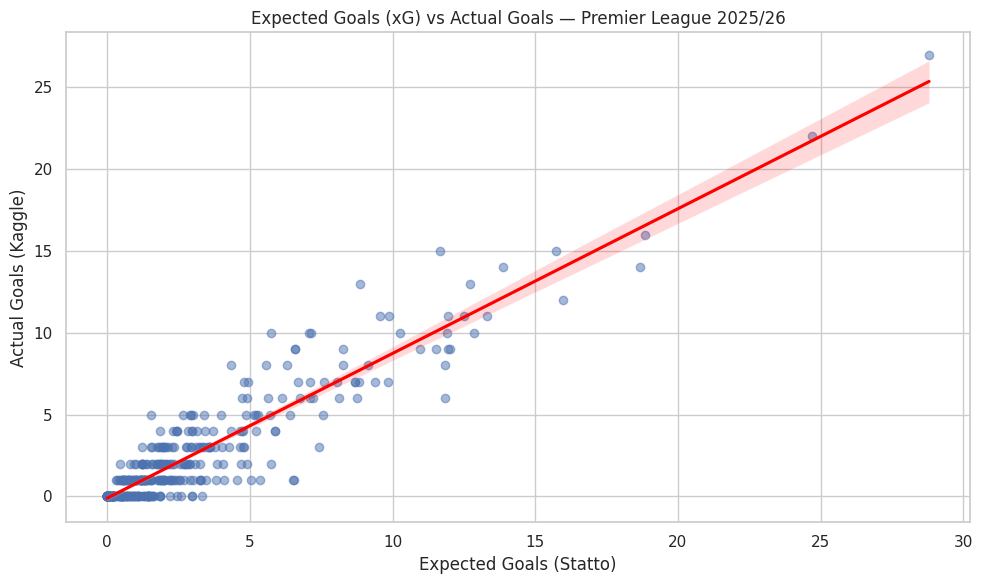

In [32]:
analysis_df = final_df[final_df["Min"] >= 450].copy()

print("Players included in analysis:", len(analysis_df))

plt.figure(figsize=(10, 6))

sns.regplot(
    data=analysis_df,
    x="xG",
    y="Gls",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.title("Expected Goals (xG) vs Actual Goals — Premier League 2025/26")
plt.xlabel("Expected Goals (Statto)")
plt.ylabel("Actual Goals (Kaggle)")

plt.tight_layout()
plt.show()

In [33]:
correlation = analysis_df["xG"].corr(analysis_df["Gls"])

print(f"Correlation between xG and actual goals: {correlation:.3f}")

Correlation between xG and actual goals: 0.929


### 7.1 Findings: Expected Goals vs Actual Goals

The scatter plot shows a  strong positive relationship between expected goals (xG) from Statto and actual goals scored from Kaggle.

The Pearson correlation coefficient was **0.929**, based on 386 Premier League players who played at least 450 minutes.

This suggests that players who accumulate higher xG generally score more goals. However, individual players can score above or below their expected goals, reflecting variation in finishing outcomes.

The analysis is observational and does not establish causation. Furthermore, both xG and goals are cumulative statistics, meaning that playing time and attacking involvement may contribute to the strong relationship.

### 7.2 Expected Assists (xA) vs Actual Assists

This visualisation examines the relationship between expected assists (xA), collected from Statto, and actual assists, obtained from Kaggle.

The same minimum playing-time threshold of 450 minutes is applied to maintain consistency with the previous visualisation.

A scatter plot with a regression line is used to examine the strength and direction of the relationship.

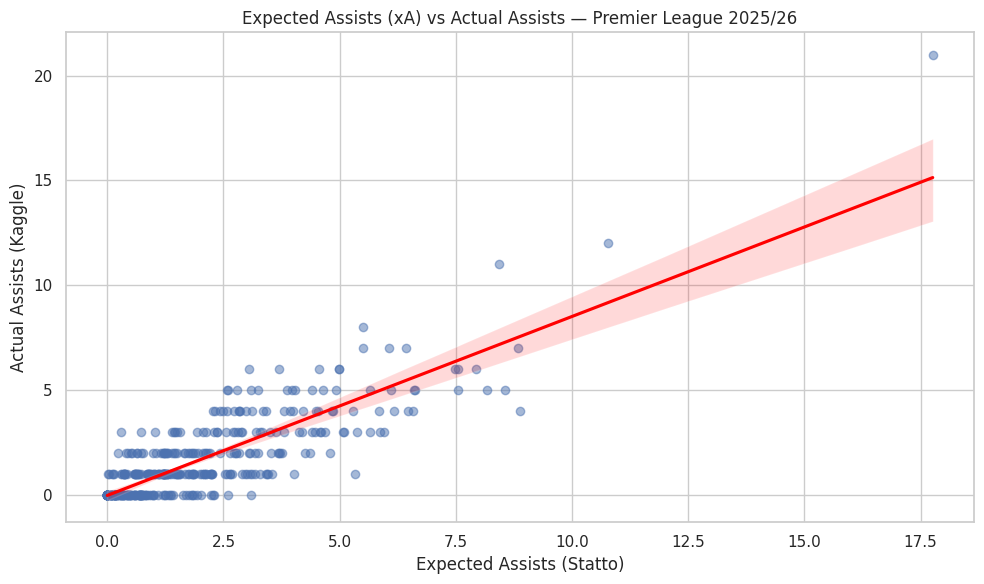

In [34]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=analysis_df,
    x="xA",
    y="Ast",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.title("Expected Assists (xA) vs Actual Assists — Premier League 2025/26")
plt.xlabel("Expected Assists (Statto)")
plt.ylabel("Actual Assists (Kaggle)")

plt.tight_layout()
plt.show()

In [35]:
xa_correlation = analysis_df["xA"].corr(analysis_df["Ast"])

print(f"Correlation between xA and actual assists: {xa_correlation:.3f}")

Correlation between xA and actual assists: 0.842


### 7.2 Findings: Expected Assists vs Actual Assists

The scatter plot shows a strong positive relationship between expected assists (xA) from Statto and actual assists from Kaggle.

The Pearson correlation coefficient was **0.842**, based on 386 Premier League players with at least 450 minutes played.

This indicates that players who generate higher expected assists generally record more actual assists.

The relationship is weaker than the correlation between xG and actual goals (0.929). One possible explanation is that actual assists depend partly on teammates converting scoring opportunities.

As with expected goals, these are cumulative statistics, so playing time and attacking involvement may influence the relationship. The results demonstrate association rather than causation.

### 7.3 Passing Accuracy vs Goal Contributions

This visualisation investigates the relationship between pass completion percentage, collected from Statto, and total goal contributions (goals plus assists), calculated using the Kaggle dataset.

A scatter plot and regression line are used to examine whether passing accuracy is associated with attacking output.

The analysis includes players with at least 450 minutes played to reduce the influence of very limited playing time.

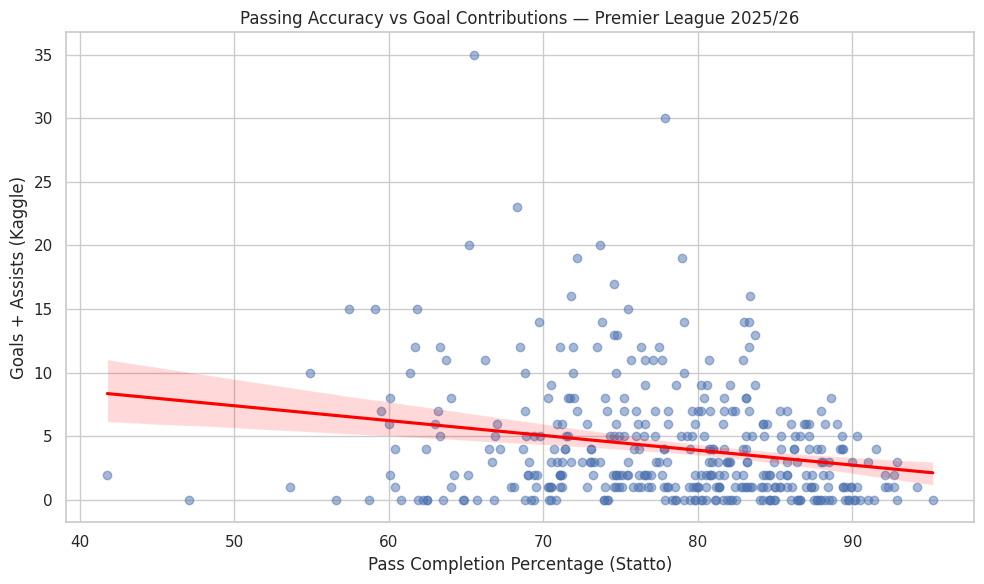

In [36]:
analysis_df["Goal_Contributions"] = (
    analysis_df["Gls"] + analysis_df["Ast"]
)


plt.figure(figsize=(10, 6))

sns.regplot(
    data=analysis_df,
    x="Pass Completion %",
    y="Goal_Contributions",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.title("Passing Accuracy vs Goal Contributions — Premier League 2025/26")
plt.xlabel("Pass Completion Percentage (Statto)")
plt.ylabel("Goals + Assists (Kaggle)")

plt.tight_layout()
plt.show()

In [37]:
passing_correlation = analysis_df[
    "Pass Completion %"
].corr(analysis_df["Goal_Contributions"])

print(
    f"Correlation between passing accuracy and goal contributions: "
    f"{passing_correlation:.3f}"
)

Correlation between passing accuracy and goal contributions: -0.215


### 7.3 Findings: Passing Accuracy vs Goal Contributions

The scatter plot shows a weak negative relationship between pass completion percentage and total goal contributions (goals plus assists).

The Pearson correlation coefficient was **−0.215**, based on 386 Premier League players with at least 450 minutes played.

Unlike expected goals and expected assists, passing accuracy does'nt show a strong positive relationship with attacking output.

One possible explanation is the influence of player positions. Defenders and defensive midfielders may complete a high percentage of passes while contributing fewer goals and assists. Attacking players may attempt more difficult passes, potentially reducing their completion percentage.

These findings suggest that passing accuracy alone is not a reliable measure of attacking performance. However, the relationship may be influenced by position, playing time and tactical responsibilities.

### 7.4 Passing Accuracy and Goal Contributions by Position

The previous analysis identified a weak negative relationship between passing accuracy and goal contributions.

Player position may influence this relationship because defenders, midfielders and forwards have different responsibilities.

To investigate this possibility, players are grouped by their primary playing position and compared using a Seaborn scatter plot.

In [38]:
analysis_df["Position_Group"] = (
    analysis_df["Pos"].str.split(",").str[0]
)

print(analysis_df["Position_Group"].value_counts())

Position_Group
MF    172
DF    132
FW     55
GK     27
Name: count, dtype: int64


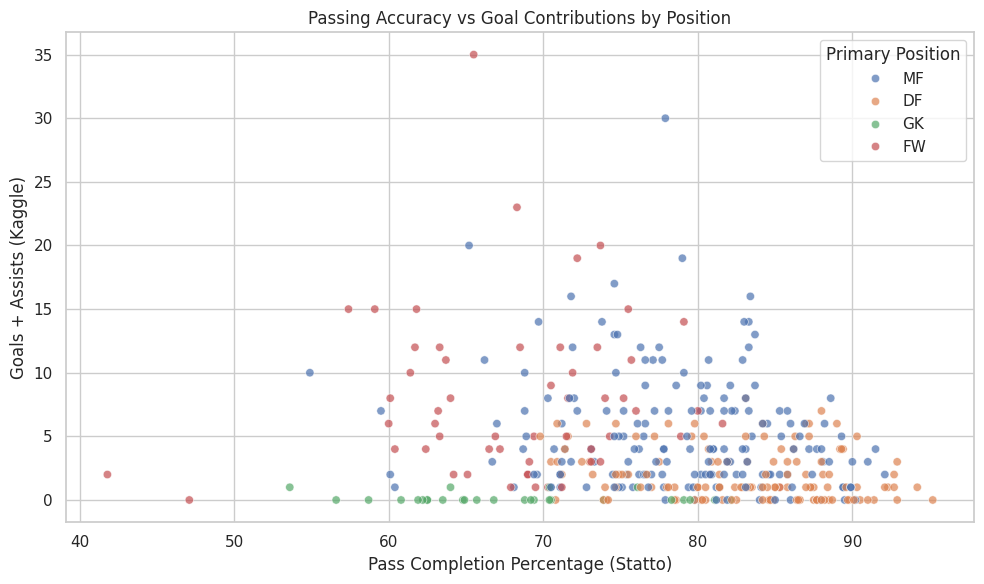

In [39]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=analysis_df,
    x="Pass Completion %",
    y="Goal_Contributions",
    hue="Position_Group",
    alpha=0.7
)

plt.title("Passing Accuracy vs Goal Contributions by Position")
plt.xlabel("Pass Completion Percentage (Statto)")
plt.ylabel("Goals + Assists (Kaggle)")
plt.legend(title="Primary Position")

plt.tight_layout()
plt.show()

In [40]:
position_summary = analysis_df.groupby(
    "Position_Group"
)[["Pass Completion %", "Goal_Contributions"]].mean()

print(position_summary.round(2))

                Pass Completion %  Goal_Contributions
Position_Group                                       
DF                          82.91                1.99
FW                          68.23                7.91
GK                          68.05                0.15
MF                          78.81                5.23


### 7.4 Findings: Influence of Player Position

The analysis suggests that player position influences the relationship between passing accuracy and attacking performance.

Defenders recorded the highest average pass completion percentage (82.91%) but relatively few goal contributions (1.99 per player). In contrast, forwards had a lower average passing accuracy (68.23%) but the highest average goal contributions (7.91).

Midfielders recorded an average passing accuracy of 78.81% and 5.23 goal contributions, while goalkeepers averaged 68.05% passing accuracy and 0.15 goal contributions.

These findings  explain the weak negative correlation (−0.215) between passing accuracy and goal contributions across all positions.

Different positions have different responsibilities. Defenders may prioritise possession retention, while forwards  attempt riskier attacking actions.

Thats why passing accuracy should not be interpreted as a direct measure of attacking performance without considering player position.

### 7.5 Controlling for Playing Time: Statistics per 90 Minutes

The previous analyses used cumulative statistics, which could be influenced by differences in playing time.

To make comparisons a bit fairer, expected goals, actual goals, expected assists and actual assists are converted into rates per 90 minutes played.

The analysis continues to include players with at least 450 minutes played to reduce the influence of very small playing-time samples.

Comparing the resulting correlations with the original correlations will help assess whether playing time contributed to the strength of the observed relationships.

In [41]:
analysis_df["xG_per90"] = analysis_df["xG"] / analysis_df["Min"] * 90

analysis_df["Goals_per90"] = analysis_df["Gls"] / analysis_df["Min"] * 90

analysis_df["xA_per90"] = analysis_df["xA"] / analysis_df["Min"] * 90

analysis_df["Assists_per90"] = analysis_df["Ast"] / analysis_df["Min"] * 90

analysis_df[
    ["Player", "xG_per90", "Goals_per90",
     "xA_per90", "Assists_per90"]
].head()

,Player,xG_per90,Goals_per90,xA_per90,Assists_per90
0,Brenden Aaronson,0.216088,0.146999,0.208003,0.183748
5,Tyler Adams,0.047208,0.101523,0.062437,0.101523
6,Tosin Adarabioyo,0.007925,0.000000,0.047547,0.000000
7,Simon Adingra,0.046861,0.137825,0.100613,0.000000
8,Amine Adli,0.293962,0.247027,0.105398,0.082342


In [42]:
print("xG vs Goals")
print("Original correlation:", round(correlation, 3))
print(
    "Per 90 correlation:",
    round(analysis_df["xG_per90"].corr(analysis_df["Goals_per90"]), 3)
)

print("\nxA vs Assists")
print("Original correlation:", round(xa_correlation, 3))
print(
    "Per 90 correlation:",
    round(analysis_df["xA_per90"].corr(analysis_df["Assists_per90"]), 3)
)

xG vs Goals
Original correlation: 0.929
Per 90 correlation: 0.862

xA vs Assists
Original correlation: 0.842
Per 90 correlation: 0.721


### 7.5 Findings: Effect of Playing Time

Adjusting statistics to a per-90-minute basis reduced both correlations.

The correlation between expected goals and actual goals decreased from 0.929 to 0.862, while the correlation between expected assists and actual assists decreased from 0.842 to 0.721.

This suggests that differences in playing time contribute to the strong relationships observed in the original analysis.

However, both relationships remain strongly positive after adjusting for minutes played. Therefore, expected goals and expected assists remain closely associated with actual attacking output even when playing time is taken into account.

These findings demonstrate the importance of considering playing time when comparing football player performance.

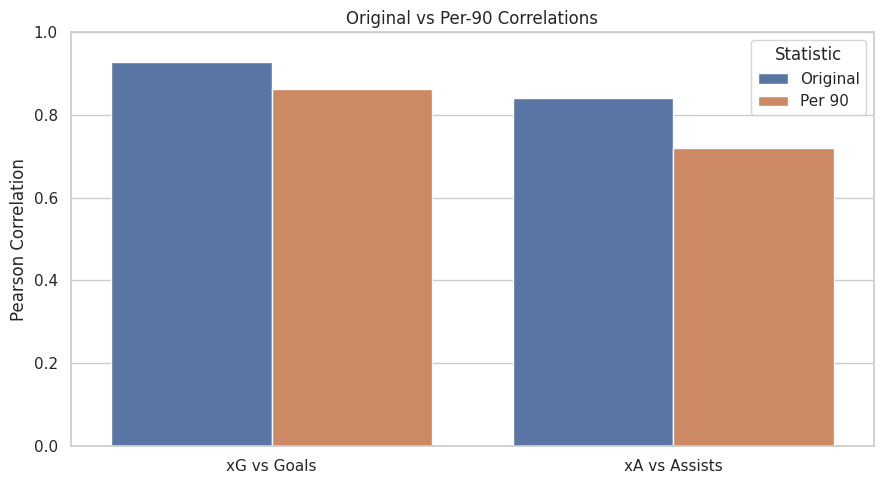

In [43]:
correlation_data = pd.DataFrame({
    "Relationship": ["xG vs Goals", "xG vs Goals",
                     "xA vs Assists", "xA vs Assists"],
    "Statistic": ["Original", "Per 90", "Original", "Per 90"],
    "Correlation": [0.929, 0.862, 0.842, 0.721]
})

plt.figure(figsize=(9, 5))

sns.barplot(
    data=correlation_data,
    x="Relationship",
    y="Correlation",
    hue="Statistic"
)

plt.title("Original vs Per-90 Correlations")
plt.ylabel("Pearson Correlation")
plt.xlabel("")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

## 8. Conclusion

This project investigated how expected goals (xG), expected assists (xA) and passing accuracy relate to player performance in the 2025/26 Premier League.

The original Kaggle dataset contained 2,839 player records across five European leagues. Additional statistics were collected from Statto using web scraping and merged with the Kaggle data using player and team names.

The merge successfully matched 530 Premier League players. After removing records with missing statistics, 511 players remained, representing 18.00% of the original Kaggle dataset and exceeding the 10% requirement.

### Key Findings

The analysis identified three main findings:

1. **Expected Goals (xG):** A very strong positive correlation (0.929) was found between xG and actual goals, suggesting that players with higher expected goals generally score more goals.

2. **Expected Assists (xA):** A strong positive correlation (0.842) was found between xA and actual assists, indicating that players who create more expected assists generally record more assists.

3. **Passing Accuracy:** A weak negative correlation (−0.215) was found between passing accuracy and total goal contributions. Further analysis suggested that players positions helped explain this relationship. Defenders had the highest average passing accuracy (82.91%) but fewer goal contributions, but forwards had lower passing accuracy (68.23%) and the highest average goal contributions.

### Effect of Playing Time

After adjusting statistics to a per-90-minute basis, the xG–goals correlation decreased from 0.929 to 0.862, while the xA–assists correlation decreased from 0.842 to 0.721.

Both relationships remained strongly positive, suggesting that playing time contributes to the original correlations but does not fully explain them.

### Limitations

Several limitations should be considered:

- Some players could not be matched between the datasets, while others had missing statistics.
- The two sources may use different statistical definitions or reporting methods.
- Players with fewer than 450 minutes were excluded from the visualisations, potentially introducing selection bias.
- Player positions were simplified into broad categories.
- Correlation does not establish causation, and factors such as team quality, tactical roles and playing time may influence performance.

### Overall Conclusion

The findings suggest that **expected goals and expected assists are strongly associated with actual attacking performance**, even after adjusting for playing time.

Passing accuracy  appears to be a less useful indicator of attacking output, particularly when comparing players across different positions.

Overall, the project shows how combining a Kaggle dataset with complementary web-scraped statistics can provide additional insights into football players performances.